# AgriScout — Environment Walkthrough
Quick interactive check of the custom Gymnasium environment.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from environment.custom_env import ACTION_NAMES, AgriScoutEnv, STRESS_THRESHOLD

env = AgriScoutEnv()
obs, info = env.reset(seed=7)
print("actions:", ACTION_NAMES)
print("observation shape:", obs.shape, "| start info:", info)

actions: ['move_north', 'move_south', 'move_east', 'move_west', 'scan', 'treat', 'charge']
observation shape: (19,) | start info: {'pos': (0, 0), 'battery': 100.0, 'wind': 0.260583064513112, 'steps': 0, 'stressed_left': 5, 'treated_ok': 0, 'treated_bad': 0}


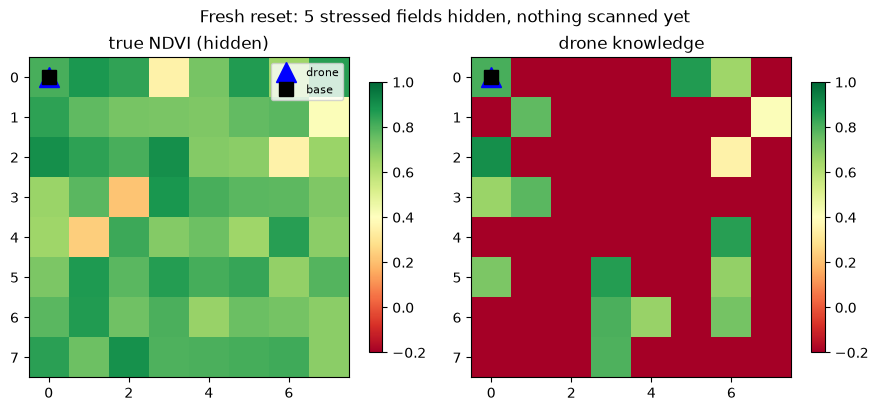

In [2]:
def show(env, title):
    # Plot the true field health next to what the drone actually knows.
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    for ax, grid, name in [(axes[0], env.ndvi, "true NDVI (hidden)"),
                           (axes[1], env.known, "drone knowledge")]:
        im = ax.imshow(grid, cmap="RdYlGn", vmin=-0.2, vmax=1.0)
        ax.plot(env.pos[1], env.pos[0], "b^", markersize=14, label="drone")
        ax.plot(env.base[1], env.base[0], "ks", markersize=10, label="base")
        ax.set_title(name)
        plt.colorbar(im, ax=ax, shrink=0.8)
    axes[0].legend(loc="upper right", fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()


show(env, "Fresh reset: 5 stressed fields hidden, nothing scanned yet")

random agent after 60 steps: return -36.0, battery 42.1, stressed left 5


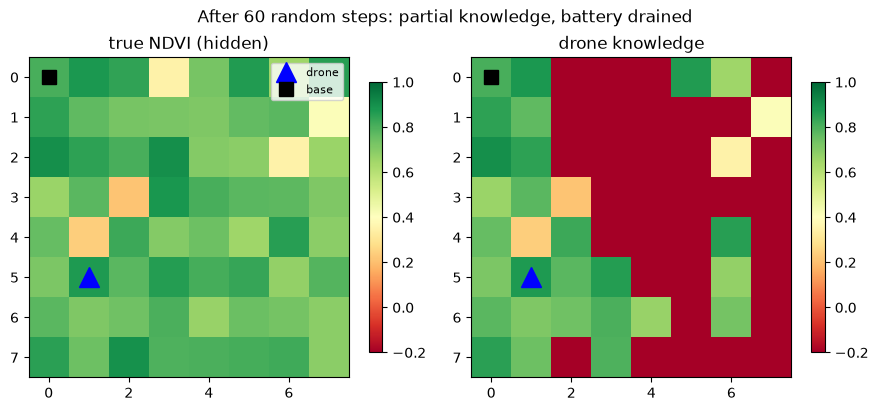

In [3]:
total = 0.0
for _ in range(60):
    obs, reward, term, trunc, info = env.step(env.action_space.sample())
    total += reward
    if term or trunc:
        break
print(f"random agent after {info['steps']} steps: return {total:.1f}, "
      f"battery {info['battery']:.1f}, stressed left {info['stressed_left']}")
show(env, "After 60 random steps: partial knowledge, battery drained")